# Semantic Segmentation: One Label per Pixel

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roboflow/supervision/blob/develop/docs/notebooks/semantic-segmentation.ipynb)

A semantic segmentation model labels every pixel of an image with a class: *road*, *building*, *sky*. It does not separate two people standing side by side, because both pixels are just `person`. Models return this as one dense map of shape `(H, W)` holding a class id per pixel.

supervision turns that map into `sv.Detections`, with one detection per class id holding a mask, a tight box and a `class_name`. Every annotator, filter and sink then works as usual. Which method to call depends on where the map comes from:

- `sv.Detections.from_semantic_segmentation` for Roboflow Inference results and raw maps. It drops background id `0` by default, reads the per-pixel confidence map and can build compact masks.
- `sv.Detections.from_transformers` for Hugging Face Transformers models. It keeps every class.

This cookbook runs four models, all trained on the 150-class ADE20K scene-parsing dataset, so their outputs are directly comparable:

- **RF-DETR**: the semantic segmentation models of the RF-DETR family, served by Roboflow Inference.
- **SegFormer**: a lightweight transformer encoder with a plain MLP decoder.
- **Mask2Former**: a mask-classification model that predicts a set of masks and classes.
- **OneFormer**: a single model that can do semantic, instance and panoptic segmentation, steered by a task prompt.

## Install required packages

`inference` runs RF-DETR and brings `torch` along, and `transformers` runs the other three models.

In [ ]:
%pip install -q inference transformers

`from_semantic_segmentation` ships in supervision `0.32.0`. Until it is released, install it from the `develop` branch. This is a separate step with `--no-deps` because `inference` currently pins `supervision<0.31`, so one `pip install` cannot resolve both.

In [ ]:
%pip install -q --no-deps "supervision @ git+https://github.com/roboflow/supervision.git@develop"

Later sections compare models and draw results, so everything is imported in one place.

In [1]:
%matplotlib inline

import urllib.request

import numpy as np
import torch
from inference import get_model
from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForUniversalSegmentation,
    OneFormerForUniversalSegmentation,
    OneFormerProcessor,
    SegformerForSemanticSegmentation,
)

import supervision as sv

print(sv.__version__)

0.32.0.dev0


## Download the sample image

Semantic models are easiest to tell apart on a scene with many classes, so this photo has a stone house, a tiled roof, a wall, trees, grass and sky. It is a validation image from the ADE20K scene-parsing dataset, which is released for non-commercial research use.

In [2]:
image_url = "https://huggingface.co/datasets/hf-internal-testing/fixtures_ade20k/resolve/main/ADE_val_00000001.jpg"
image_path = "ade20k-house.jpg"
urllib.request.urlretrieve(image_url, image_path)

('ade20k-house.jpg', <http.client.HTTPMessage at 0x11fe75af0>)

The models take a Pillow image, and supervision annotators take a BGR array, so the photo is kept in both forms.

In [3]:
pil_image = Image.open(image_path).convert("RGB")
image = sv.pillow_to_cv2(pil_image)
height, width = image.shape[:2]
print(f"Image size: {width}x{height}")

Image size: 683x512


The next plot shows the unannotated photo, as a reference for judging the masks below.

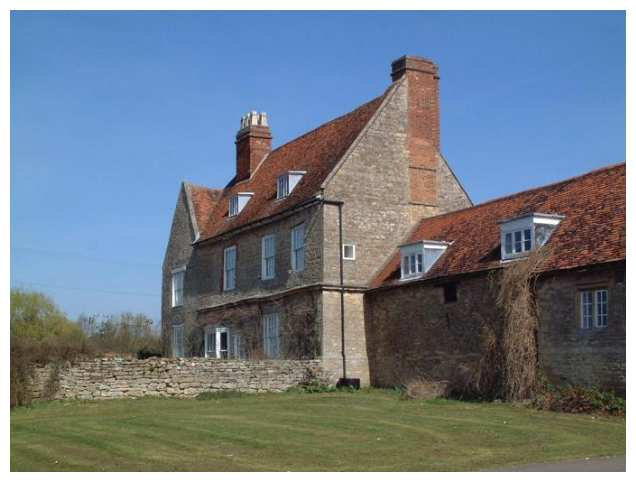

In [4]:
sv.plot_image(image, size=(10, 6))

The sky and the building take up most of the frame, while the trees, the wall and the small plants on the right are the harder details.

## Shared setup

The Hugging Face models run on the device chosen here, while Inference picks its own. Inference is much faster on a GPU, but the small checkpoints here also finish on a CPU.

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on {device}")

Running on cpu


`LabelAnnotator` reads `class_name` from the detections on its own. The sky wraps around the house, so each label is placed at its class's centre of mass rather than at a corner of a frame-wide box.

In [6]:
mask_annotator = sv.MaskAnnotator(opacity=0.6)
label_annotator = sv.LabelAnnotator(
    text_position=sv.Position.CENTER_OF_MASS, text_scale=0.5, text_padding=4
)


def annotate(scene: np.ndarray, detections: sv.Detections) -> np.ndarray:
    """Draw one coloured mask per class and write the class name on it."""
    annotated = mask_annotator.annotate(scene.copy(), detections)
    return label_annotator.annotate(annotated, detections)

## RF-DETR with Roboflow Inference

RF-DETR semantic segmentation comes in six sizes, `rfdetr-sem-nano` to `rfdetr-sem-2xlarge`, pretrained on ADE20K. The smallest one downloads quickly and runs on a CPU.

In [7]:
rfdetr = get_model("rfdetr-sem-nano")

`infer` returns one result per image. The result holds the map as a base64-encoded PNG, the class names and a per-pixel confidence map, so nothing needs unpacking by hand.

In [8]:
rfdetr_result = rfdetr.infer(pil_image)[0]

`from_semantic_segmentation` reads all three fields from the result. ADE20K here reserves id `0` for background, so the default `background_id=0` is the right setting.

In [9]:
rfdetr_detections = sv.Detections.from_semantic_segmentation(rfdetr_result)
print(list(map(str, rfdetr_detections["class_name"])))

['wall', 'sky', 'tree', 'road', 'grass', 'house']


The confidence map gives each detection the mean confidence of its pixels, which the other three models below do not report through supervision.

In [10]:
for name, confidence in zip(rfdetr_detections["class_name"], rfdetr_detections.confidence):
    print(f"{str(name):<8} {confidence:.3f}")

wall     0.862
sky      0.987
tree     0.947
road     0.926
grass    0.975
house    0.963


The next plot shows how the smallest RF-DETR divides the scene.

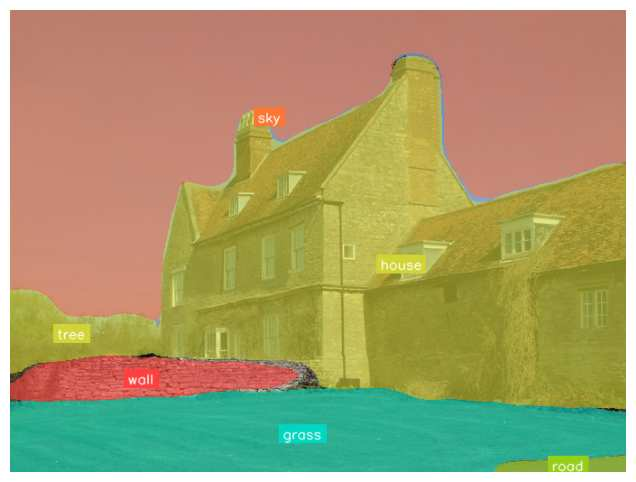

In [11]:
sv.plot_image(annotate(image, rfdetr_detections), size=(10, 6))

The outlines of the house, the wall and the lawn are tight even at this size. RF-DETR names the main structure `house` rather than `building`, and it reports no small `plant` regions. Colours follow the class id, so `tree` and `house` happen to look alike here.

Any semantic segmentation model deployed on Roboflow goes through the same call, with its own model id. `sv.Detections.from_inference` does not accept this response, because it holds one map instead of a list of objects, and it raises an error that points to `from_semantic_segmentation`.

## SegFormer

SegFormer pairs a hierarchical transformer encoder with a small all-MLP decoder, which keeps it fast.

In [12]:
segformer_name = "nvidia/segformer-b2-finetuned-ade-512-512"
segformer_processor = AutoImageProcessor.from_pretrained(segformer_name)
segformer = SegformerForSemanticSegmentation.from_pretrained(segformer_name).to(device)

Gradients are not needed for inference, so disabling them saves memory.

In [13]:
inputs = segformer_processor(images=pil_image, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = segformer(**inputs)

The model predicts logits at a quarter of the input size. `post_process_semantic_segmentation` upsamples them to the image size and takes the most likely class per pixel, which gives the `(H, W)` map.

In [14]:
segformer_map = segformer_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
print(segformer_map.shape)

torch.Size([512, 683])


`from_transformers` takes that tensor and the model's `id2label`. Nothing else is needed.

In [15]:
segformer_detections = sv.Detections.from_transformers(
    segformer_map, id2label=segformer.config.id2label
)
print(list(map(str, segformer_detections["class_name"])))

['wall', 'building', 'sky', 'tree', 'road', 'grass', 'plant']


The next plot shows whether the masks follow the outlines of the house, the wall and the lawn.

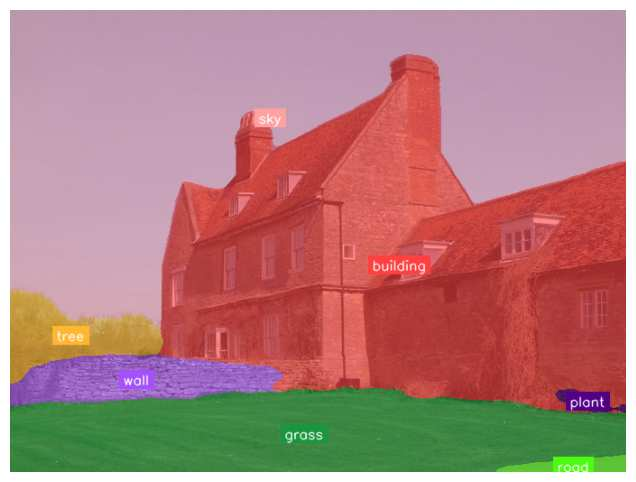

In [16]:
sv.plot_image(annotate(image, segformer_detections), size=(10, 6))

The large regions follow their outlines closely. The `sky` label lands on the chimney because the sky surrounds the house, so its centre of mass falls inside the building.

Each detection is an ordinary `sv.Detections` row, so the area of each mask directly gives the share of the image taken by each class.

In [17]:
coverage = segformer_detections.area / (height * width)
for name, share in sorted(
    zip(segformer_detections["class_name"], coverage), key=lambda item: -item[1]
)[:5]:
    print(f"{str(name):<12} {share:6.1%}")

building      39.0%
sky           38.7%
grass         15.3%
wall           3.5%
tree           2.6%


## Mask2Former

Mask2Former predicts a fixed set of masks, each with a class score, and combines them into the semantic map. The checkpoint below is the semantic-segmentation variant.

In [18]:
mask2former_name = "facebook/mask2former-swin-tiny-ade-semantic"
mask2former_processor = AutoImageProcessor.from_pretrained(mask2former_name)
mask2former = AutoModelForUniversalSegmentation.from_pretrained(mask2former_name).to(
    device
)

The inference call is the same as for SegFormer.

In [19]:
inputs = mask2former_processor(images=pil_image, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = mask2former(**inputs)

Post-processing combines the predicted masks into the same `(H, W)` tensor, so the supervision call does not change.

In [20]:
mask2former_map = mask2former_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
mask2former_detections = sv.Detections.from_transformers(
    mask2former_map, id2label=mask2former.config.id2label
)
print(list(map(str, mask2former_detections["class_name"])))

['wall', 'building', 'sky', 'tree', 'road', 'grass', 'plant', 'path']


The next plot shows how Mask2Former treats the small regions at the bottom of the frame.

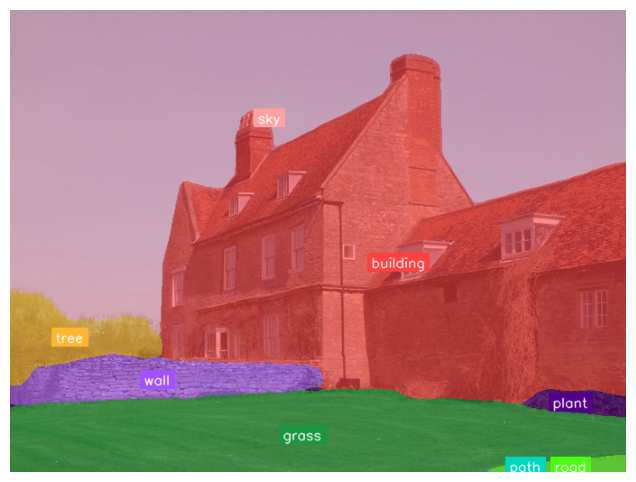

In [21]:
sv.plot_image(annotate(image, mask2former_detections), size=(10, 6))

The large regions match SegFormer, and the paved corner at the bottom right is split into `road` and `path`.

## OneFormer

OneFormer is a single network for semantic, instance and panoptic segmentation, so it needs to be told which output to produce.

In [22]:
oneformer_name = "shi-labs/oneformer_ade20k_swin_tiny"
oneformer_processor = OneFormerProcessor.from_pretrained(oneformer_name)
oneformer = OneFormerForUniversalSegmentation.from_pretrained(oneformer_name).to(device)

The text prompt `task_inputs=["semantic"]` selects the output. Only this processor call differs from the models above.

In [23]:
inputs = oneformer_processor(
    images=pil_image, task_inputs=["semantic"], return_tensors="pt"
).to(device)
with torch.no_grad():
    outputs = oneformer(**inputs)

The result is again one `(H, W)` tensor for the same supervision call.

In [24]:
oneformer_map = oneformer_processor.post_process_semantic_segmentation(
    outputs, target_sizes=[(height, width)]
)[0]
oneformer_detections = sv.Detections.from_transformers(
    oneformer_map, id2label=oneformer.config.id2label
)
print(list(map(str, oneformer_detections["class_name"])))

['wall', 'building', 'sky', 'tree', 'road, route', 'grass', 'plant', 'house']


The next plot shows how OneFormer reads the ivy growing on the right-hand wall.

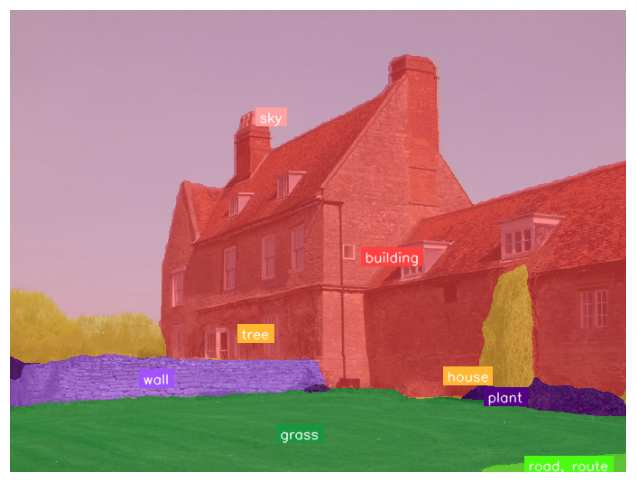

In [25]:
sv.plot_image(annotate(image, oneformer_detections), size=(10, 6))

OneFormer paints the ivy as `tree` and adds a small `house` region, which SegFormer and Mask2Former do not report.

## Compare the models

The models share one output type, so a side-by-side view takes one list comprehension. The next plot answers where they visibly differ.

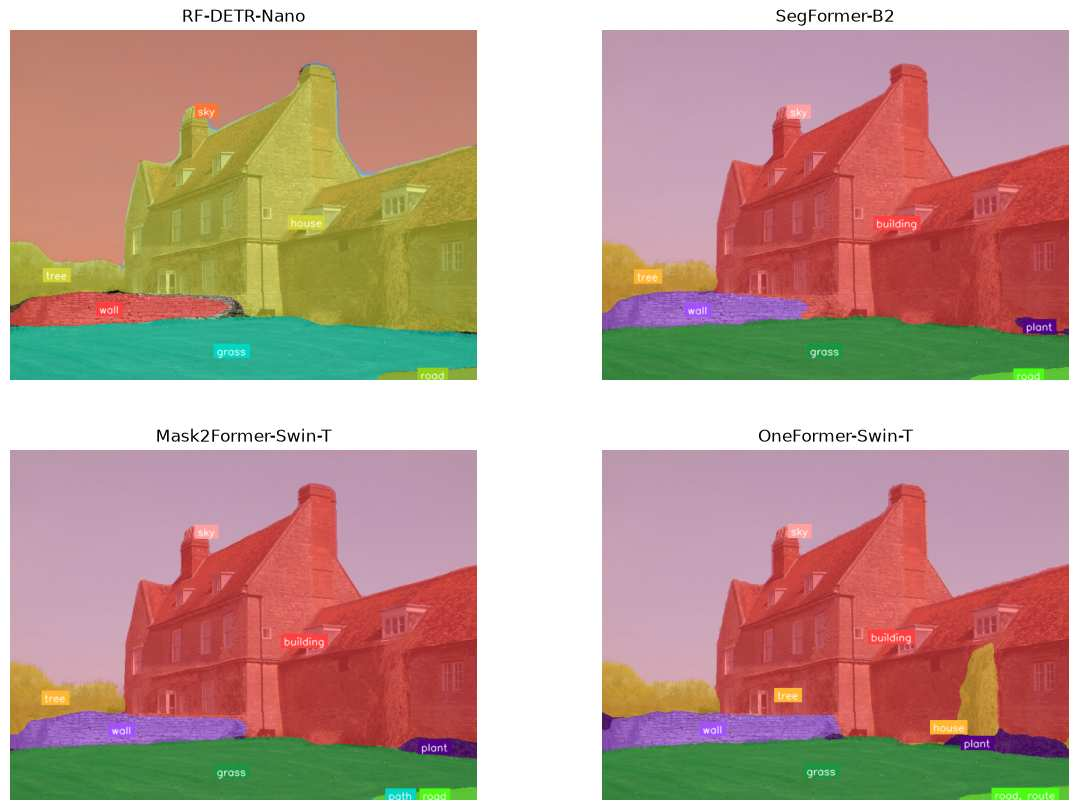

In [26]:
results = {
    "RF-DETR-Nano": rfdetr_detections,
    "SegFormer-B2": segformer_detections,
    "Mask2Former-Swin-T": mask2former_detections,
    "OneFormer-Swin-T": oneformer_detections,
}

sv.plot_images_grid(
    images=[annotate(image, detections) for detections in results.values()],
    grid_size=(2, 2),
    titles=list(results),
    size=(14, 10),
)

The region outlines look alike across all four models. RF-DETR's colours differ only because its class ids are one higher and the palette follows the id. The real differences are the name of the house and the small regions: the ivy and the corner at the bottom right.

The Hugging Face checkpoints spell some class names differently (for example `road` and `road, route`), so comparing class ids avoids counting one class as two. RF-DETR reserves id `0` for background, which moves each ADE20K class up by one, so its ids are shifted back to line up with the others.

In [27]:
class_ids = {name: set(d.class_id.tolist()) for name, d in results.items()}
class_ids["RF-DETR-Nano"] = set((rfdetr_detections.class_id - 1).tolist())

Classes reported by every model are the safe part of the scene, and classes reported by only one model show where to look closer.

In [28]:
id2label = segformer.config.id2label
shared = set.intersection(*class_ids.values())
print(f"All four report: {sorted(id2label[i] for i in shared)}")
for name, ids in class_ids.items():
    others = set.union(*(other for n, other in class_ids.items() if n != name))
    print(f"Only {name}: {sorted(id2label[i] for i in ids - others)}")

All four report: ['grass', 'road', 'sky', 'tree', 'wall']
Only RF-DETR-Nano: []
Only SegFormer-B2: []
Only Mask2Former-Swin-T: ['path']
Only OneFormer-Swin-T: []


Class lists hide how much area a disagreement covers, so the share of pixels with the same class id measures it directly. RF-DETR's map is rebuilt from its masks with the same shift. Its background pixels stay at `-1`, which counts them as disagreement.

In [29]:
rfdetr_map = np.full((height, width), -1)
for class_id, mask in zip(rfdetr_detections.class_id, rfdetr_detections.mask):
    rfdetr_map[mask] = class_id - 1

Each pair of models is compared once.

In [30]:
maps = {
    "RF-DETR-Nano": rfdetr_map,
    "SegFormer-B2": segformer_map.cpu().numpy(),
    "Mask2Former-Swin-T": mask2former_map.cpu().numpy(),
    "OneFormer-Swin-T": oneformer_map.cpu().numpy(),
}
names = list(maps)
for i, first in enumerate(names):
    for second in names[i + 1 :]:
        agreement = float((maps[first] == maps[second]).mean())
        print(f"{first} vs {second}: {agreement:.1%} of pixels agree")

RF-DETR-Nano vs SegFormer-B2: 59.6% of pixels agree
RF-DETR-Nano vs Mask2Former-Swin-T: 59.5% of pixels agree
RF-DETR-Nano vs OneFormer-Swin-T: 59.6% of pixels agree
SegFormer-B2 vs Mask2Former-Swin-T: 98.5% of pixels agree
SegFormer-B2 vs OneFormer-Swin-T: 95.7% of pixels agree
Mask2Former-Swin-T vs OneFormer-Swin-T: 96.3% of pixels agree


The three Hugging Face models agree on 96-98% of pixels. RF-DETR's lower score is mostly one naming difference: SegFormer's `building` covers 39.0% of the image, and RF-DETR calls that region `house`.

## Large images: compact masks

A dense mask is one `(H, W)` boolean array per class, so a 4K image with 40 classes holds 40 full-size arrays. `from_semantic_segmentation` also accepts a raw map, and with `compact_masks=True` it stores each mask as a run-length encoded crop, built one class at a time. `background_id=None` keeps ADE20K's id `0`, which is the class `wall` rather than background.

In [31]:
compact_detections = sv.Detections.from_semantic_segmentation(
    segformer_map,
    class_map=segformer.config.id2label,
    background_id=None,
    compact_masks=True,
)
print(type(compact_detections.mask).__name__)

CompactMask


Compact masks only change the storage, so they must decode to exactly the pixels of the dense masks.

In [32]:
print(np.array_equal(np.asarray(compact_detections.mask), segformer_detections.mask))

True


## What next

- Filter classes with the usual `sv.Detections` indexing, for example `detections[detections["class_name"] == "sky"]`.
- Try `sv.PolygonAnnotator` or `sv.HaloAnnotator` for other looks.
- Semantic segmentation cannot count objects, because it does not separate them. For that, use an instance segmentation model with `from_inference`, `from_ultralytics` or `from_transformers`.